# AeroGuard: Milestone 2 — Exploratory Data Analysis & Sensor Degradation Analysis

**Author:** Senior Machine Learning Engineer / Applied ML Research Team  
**Dataset:** NASA C-MAPSS Turbofan Degradation Simulation (FD001)  
**Objective:** Characterize fleet lifespans, isolate invariant sensors, analyze correlation structure, and mathematically profile degradation trajectories.

---

## 1. Physical and Mathematical Foundations

### 1.1 The High-Pressure Compressor (HPC) Degradation Mechanism
In C-MAPSS sub-dataset **FD001**, degradation is isolated to a single subsystem under a single operating regime (Sea Level, nominal flight):
- **Fault Mode:** High-Pressure Compressor (HPC) wear.
- **Physical Dynamics:** As the HPC blades erode and clearances increase, aerodynamic and isentropic efficiency degrades ($\eta_{\text{HPC}} \downarrow$).
- **Thermal Compensation:** To maintain commanded thrust, the engine control unit increases fuel flow ($s_{13} \uparrow$). Higher combustor heat release leads to elevated turbine inlet and outlet gas temperatures:
  - $s_2$: Total temperature at LPC outlet ($T_{24}$)
  - $s_3$: Total temperature at HPC outlet ($T_{30}$)
  - $s_4$: Total temperature at LPT outlet ($T_{50}$)
- **Pneumatic Degradation:** Compressor pressure ratios decline:
  - $s_7$: Total pressure at HPC outlet ($P_{30} \downarrow$)
  - $s_{12}$: Static pressure at HPC outlet ($Ps_{30} \downarrow$)

### 1.2 Mathematical Formulation of Trajectories
Let engine $i \in \{1, 2, \dots, 100\}$ undergo operational cycles $t \in \{1, 2, \dots, T_i\}$, where $T_i$ represents the final cycle prior to system failure.
The observation vector at cycle $t$ is:
$$\mathbf{x}_t^{(i)} = [s_{1,t}^{(i)}, s_{2,t}^{(i)}, \dots, s_{21,t}^{(i)}, \text{setting}_{1,t}^{(i)}, \dots]^T \in \mathbb{R}^D$$

The ground-truth Remaining Useful Life is defined as:
$$RUL(i, t) = T_i - t$$


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project modules are resolvable
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root))

from src.data.loader import (
    load_fd001_raw,
    ALL_COLUMNS,
    INDEX_COLUMNS,
    SETTING_COLUMNS,
    SENSOR_COLUMNS
)

# Ingest raw dataset with verified schema
train_df, test_df, rul_series = load_fd001_raw(project_root / 'data' / 'raw')
print(f'Train matrix dimensions: {train_df.shape} across {train_df["engine_id"].nunique()} engines')
print(f'Test matrix dimensions:  {test_df.shape} across {test_df["engine_id"].nunique()} engines')
print(f'Official Test RUL vector: {rul_series.shape[0]} engines')


Train matrix dimensions: (20631, 26) across 100 engines
Test matrix dimensions:  (13096, 26) across 100 engines
Official Test RUL vector: 100 engines


## 2. Fleet Lifespan & Longevity Analysis

In run-to-failure simulations, initial wear and manufacturing variation cause variance in the lifespan $T_i$.
Let:
$$T_i = \max_{t} \{t \mid (i, t) \in \mathcal{D}_{\text{train}}\}$$

We examine the five-number summary: $\min(T_i), Q_1(T_i), \text{median}(T_i), Q_3(T_i), \max(T_i)$.


In [2]:
train_lifespans = train_df.groupby("engine_id")["cycle"].max()
test_observed = test_df.groupby("engine_id")["cycle"].max()

lifespan_stats = pd.DataFrame({
    'Metric': ['Engine Count', 'Min Lifecycle (cycles)', '25th Percentile (Q1)', 
               'Median Lifecycle', 'Mean Lifecycle', '75th Percentile (Q3)', 
               'Max Lifecycle (cycles)', 'Standard Deviation (σ)'],
    'Training Fleet (Run-to-Failure)': [
        len(train_lifespans),
        int(train_lifespans.min()),
        float(train_lifespans.quantile(0.25)),
        float(train_lifespans.median()),
        round(float(train_lifespans.mean()), 2),
        float(train_lifespans.quantile(0.75)),
        int(train_lifespans.max()),
        round(float(train_lifespans.std()), 2)
    ],
    'Test Fleet (Truncated History)': [
        len(test_observed),
        int(test_observed.min()),
        float(test_observed.quantile(0.25)),
        float(test_observed.median()),
        round(float(test_observed.mean()), 2),
        float(test_observed.quantile(0.75)),
        int(test_observed.max()),
        round(float(test_observed.std()), 2)
    ]
})
lifespan_stats


,Metric,Training Fleet (Run-to-Failure),Test Fleet (Truncated History)
0,Engine Count,100.00,100.00
1,Min Lifecycle (cycles),128.00,31.00
2,25th Percentile (Q1),177.00,88.75
3,Median Lifecycle,199.00,133.50
4,Mean Lifecycle,206.31,130.96
5,75th Percentile (Q3),229.25,164.25
6,Max Lifecycle (cycles),362.00,303.00
7,Standard Deviation (σ),46.34,53.59


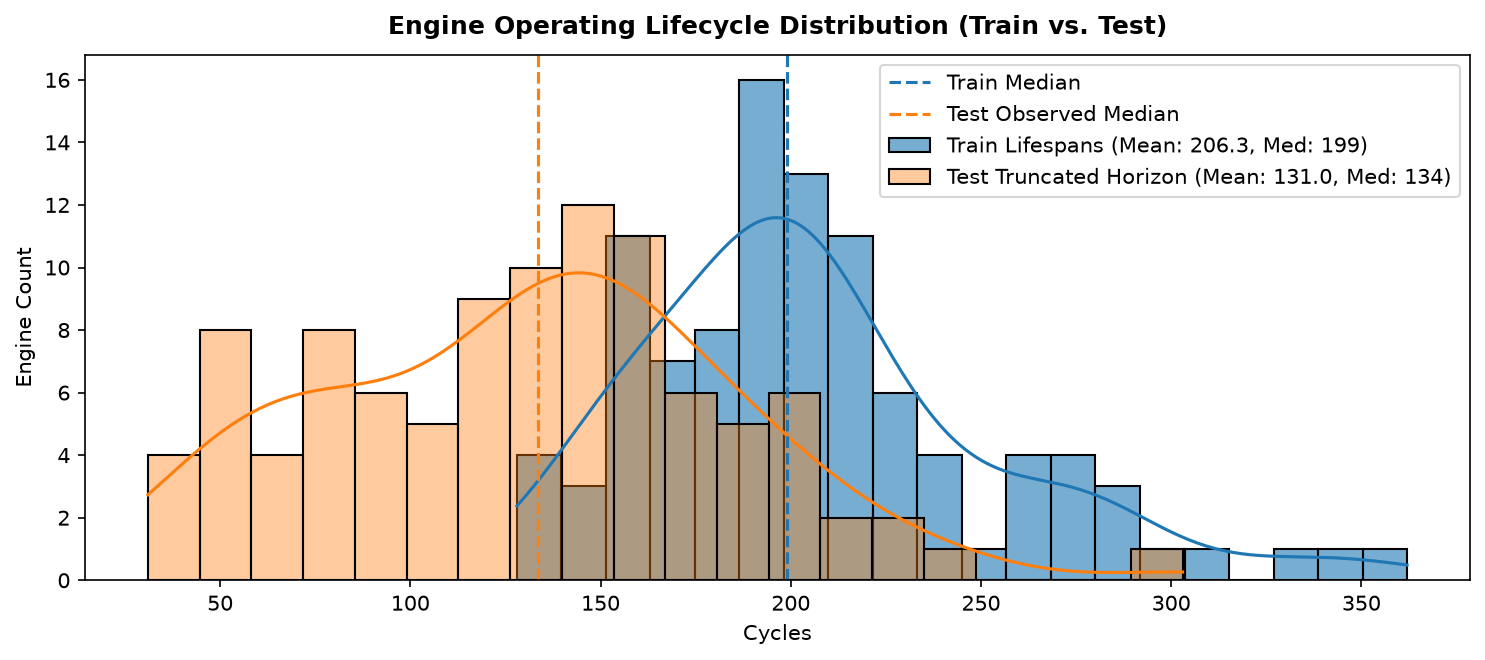

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=150)
sns.histplot(train_lifespans, bins=20, kde=True, color='#1f77b4', label=f'Train Lifespans (Mean: {train_lifespans.mean():.1f}, Med: {train_lifespans.median():.0f})', alpha=0.6, ax=ax)
sns.histplot(test_observed, bins=20, kde=True, color='#ff7f0e', label=f'Test Truncated Horizon (Mean: {test_observed.mean():.1f}, Med: {test_observed.median():.0f})', alpha=0.4, ax=ax)
ax.axvline(train_lifespans.median(), color='#1f77b4', linestyle='--', linewidth=1.5, label='Train Median')
ax.axvline(test_observed.median(), color='#ff7f0e', linestyle='--', linewidth=1.5, label='Test Observed Median')
ax.set_title('Engine Operating Lifecycle Distribution (Train vs. Test)', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Cycles', fontsize=10)
ax.set_ylabel('Engine Count', fontsize=10)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


## 3. Sensor Variability & Invariant Channel Pruning

### 3.1 Variance Formulation
For sensor channel $j$ across all $N$ observations:
$$\mu_j = \frac{1}{N} \sum_{k=1}^N x_{k,j}, \quad \sigma_j = \sqrt{\frac{1}{N-1} \sum_{k=1}^N (x_{k,j} - \mu_j)^2}$$

Channels with $\sigma_j \approx 0$ convey zero mutual information with the degradation state:
$$I(X_j; \text{RUL}) = 0$$
Retaining them creates singular covariance matrices in linear models and adds noise dimensions in distance-based algorithms.


In [4]:
stds = train_df[SETTING_COLUMNS + SENSOR_COLUMNS].std()
variability_df = pd.DataFrame({
    'Channel': stds.index,
    'Std Dev (σ)': stds.values,
    'Min': train_df[SETTING_COLUMNS + SENSOR_COLUMNS].min().values,
    'Max': train_df[SETTING_COLUMNS + SENSOR_COLUMNS].max().values,
    'Zero/Near-Zero Variance': stds.values < 1e-4
}).sort_values('Std Dev (σ)')

invariant_channels = variability_df[variability_df['Zero/Near-Zero Variance']]['Channel'].tolist()
print(f'Identified {len(invariant_channels)} invariant channels (σ < 1e-4): {invariant_channels}')
variability_df.head(10)


Identified 7 invariant channels (σ < 1e-4): ['s_1', 'setting_3', 's_10', 's_19', 's_18', 's_16', 's_5']


,Channel,Std Dev (σ),Min,Max,Zero/Near-Zero Variance
3,s_1,0.000000e+00,518.6700,518.6700,True
2,setting_3,0.000000e+00,100.0000,100.0000,True
12,s_10,0.000000e+00,1.3000,1.3000,True
21,s_19,0.000000e+00,100.0000,100.0000,True
20,s_18,0.000000e+00,2388.0000,2388.0000,True
18,s_16,3.469531e-18,0.0300,0.0300,True
7,s_5,5.329200e-15,14.6200,14.6200,True
1,setting_2,2.930621e-04,-0.0006,0.0006,False
8,s_6,1.388985e-03,21.6000,21.6100,False
0,setting_1,2.187313e-03,-0.0087,0.0087,False


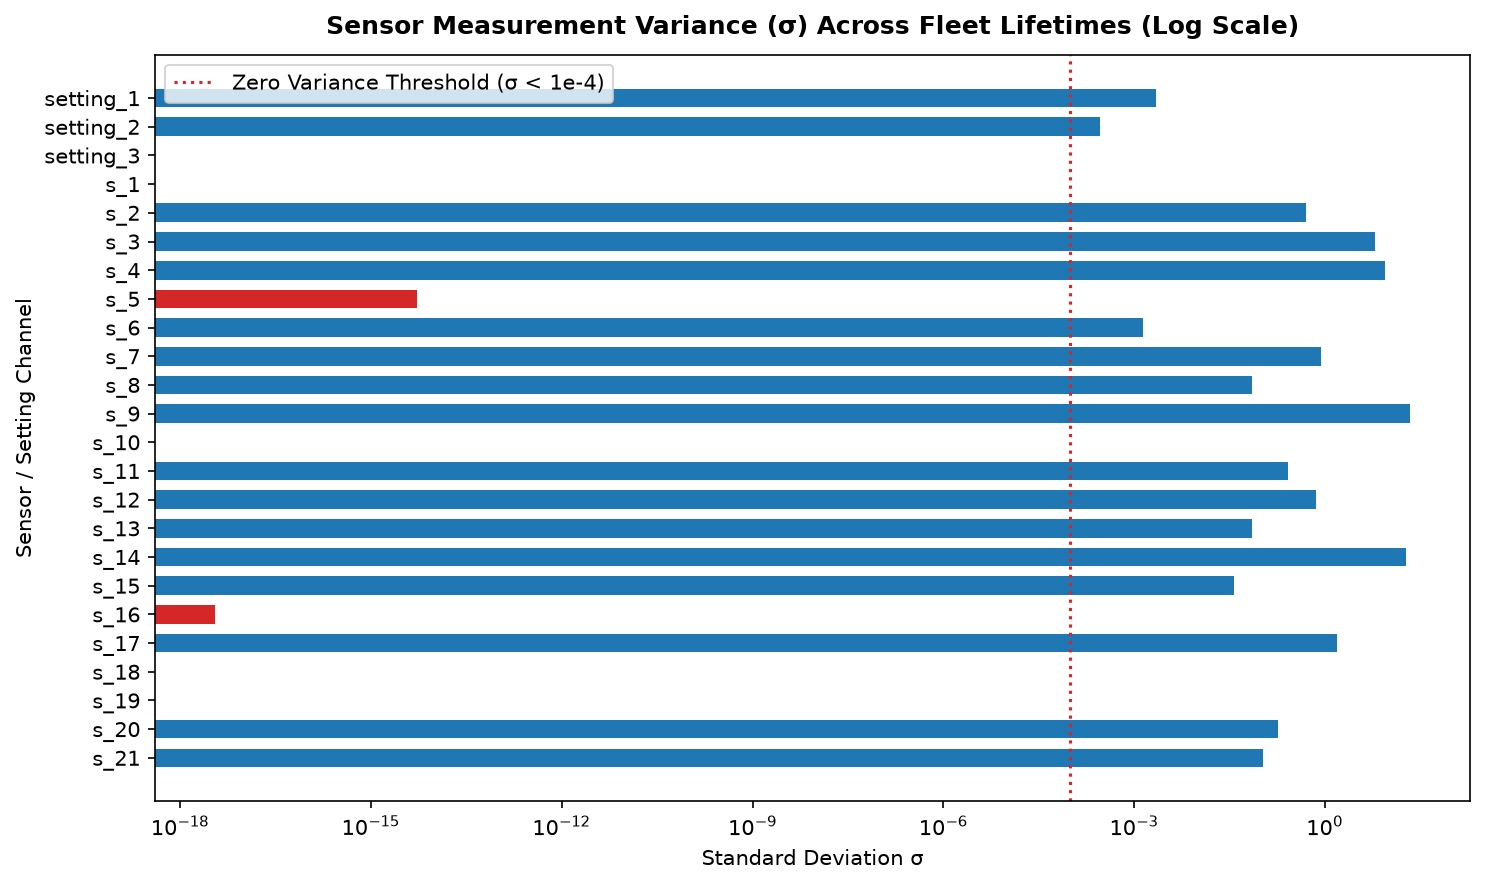

In [5]:
colors = ['#d62728' if s < 1e-4 else '#1f77b4' for s in stds]
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)
ax.barh(stds.index[::-1], stds.values[::-1], color=colors[::-1], height=0.65)
ax.set_xscale('log')
ax.axvline(1e-4, color='#d62728', linestyle=':', label='Zero Variance Threshold (σ < 1e-4)')
ax.set_title('Sensor Measurement Variance (σ) Across Fleet Lifetimes (Log Scale)', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('Standard Deviation σ', fontsize=10)
ax.set_ylabel('Sensor / Setting Channel', fontsize=10)
ax.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


## 4. Pearson Correlation Analysis & Co-Linearity Structure

For informative dynamic sensors, we compute pairwise Pearson correlation:
$$r_{j,k} = \frac{\sum_{m=1}^N (x_{m,j} - \bar{x}_j)(x_{m,k} - \bar{x}_k)}{\sqrt{\sum_{m=1}^N (x_{m,j} - \bar{x}_j)^2} \sqrt{\sum_{m=1}^N (x_{m,k} - \bar{x}_k)^2}}$$


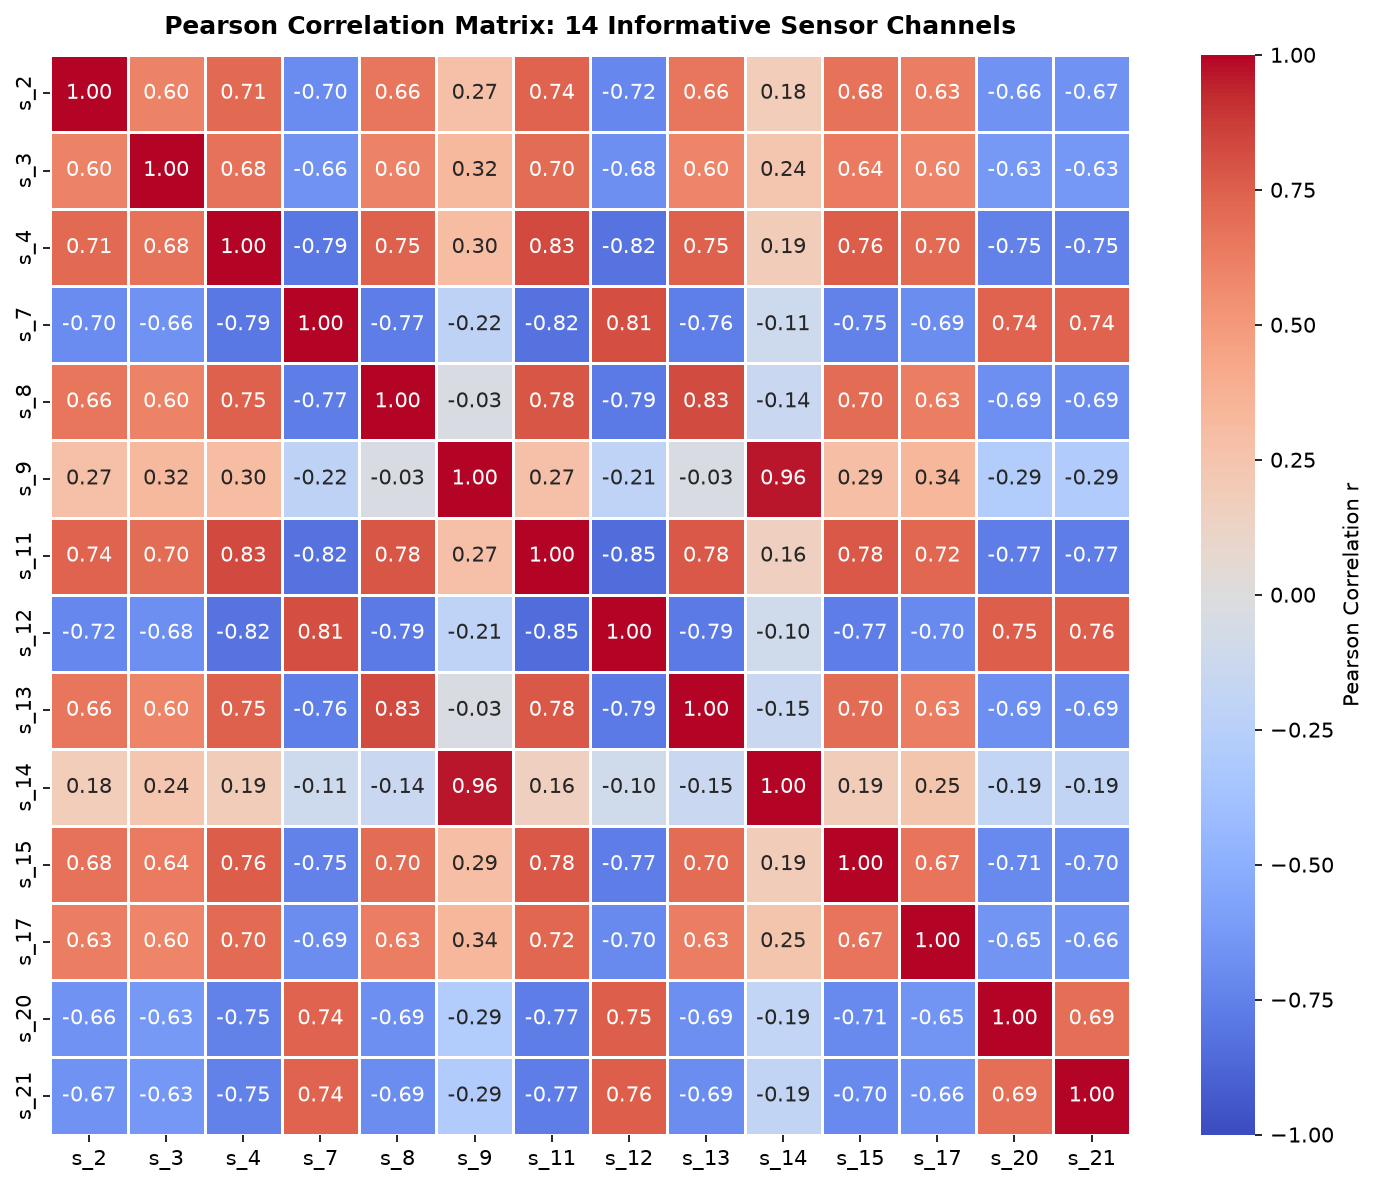

In [6]:
# Also exclude s_6 as it is quasi-constant (only 2 distinct discrete levels: 21.60 and 21.61)
informative_sensors = [col for col in SENSOR_COLUMNS if stds[col] >= 1e-4 and col != 's_6']
corr_matrix = train_df[informative_sensors].corr(method='pearson')

fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            cbar_kws={'label': 'Pearson Correlation r'}, square=True, ax=ax, linewidths=0.5)
ax.set_title('Pearson Correlation Matrix: 14 Informative Sensor Channels', fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


### 4.1 Observations on Sensor Clusters
1. **Thermal Degradation Cluster ($s_2, s_3, s_4, s_{11}, s_{17}$):**
   - High mutual positive correlation ($r > 0.70$).
   - Reflects the thermodynamic reality: as HPC efficiency drops, gas path temperatures across all turbine stages rise synchronously.
2. **Pressure & Speed Depletion Cluster ($s_7, s_8, s_{12}, s_{13}, s_{20}, s_{21}$):**
   - Strong negative correlation with thermal sensors ($r < -0.75$).
   - Reflects loss of compressor pressure head ($P_{30}, Ps_{30}$) and flow capacity.


## 5. Temporal Trajectory Inspection Across Differing Lifespans

We inspect temporal trajectories of key degradation indicators across 3 representative engines:
- **Engine 39 (Short Lifespan):** $T_{39} = 128$ cycles (rapid failure)
- **Engine 69 (Median Lifespan):** $T_{69} = 199$ cycles
- **Engine 69 (Long Lifespan):** $T_{69} = 362$ cycles (prolonged resilience)


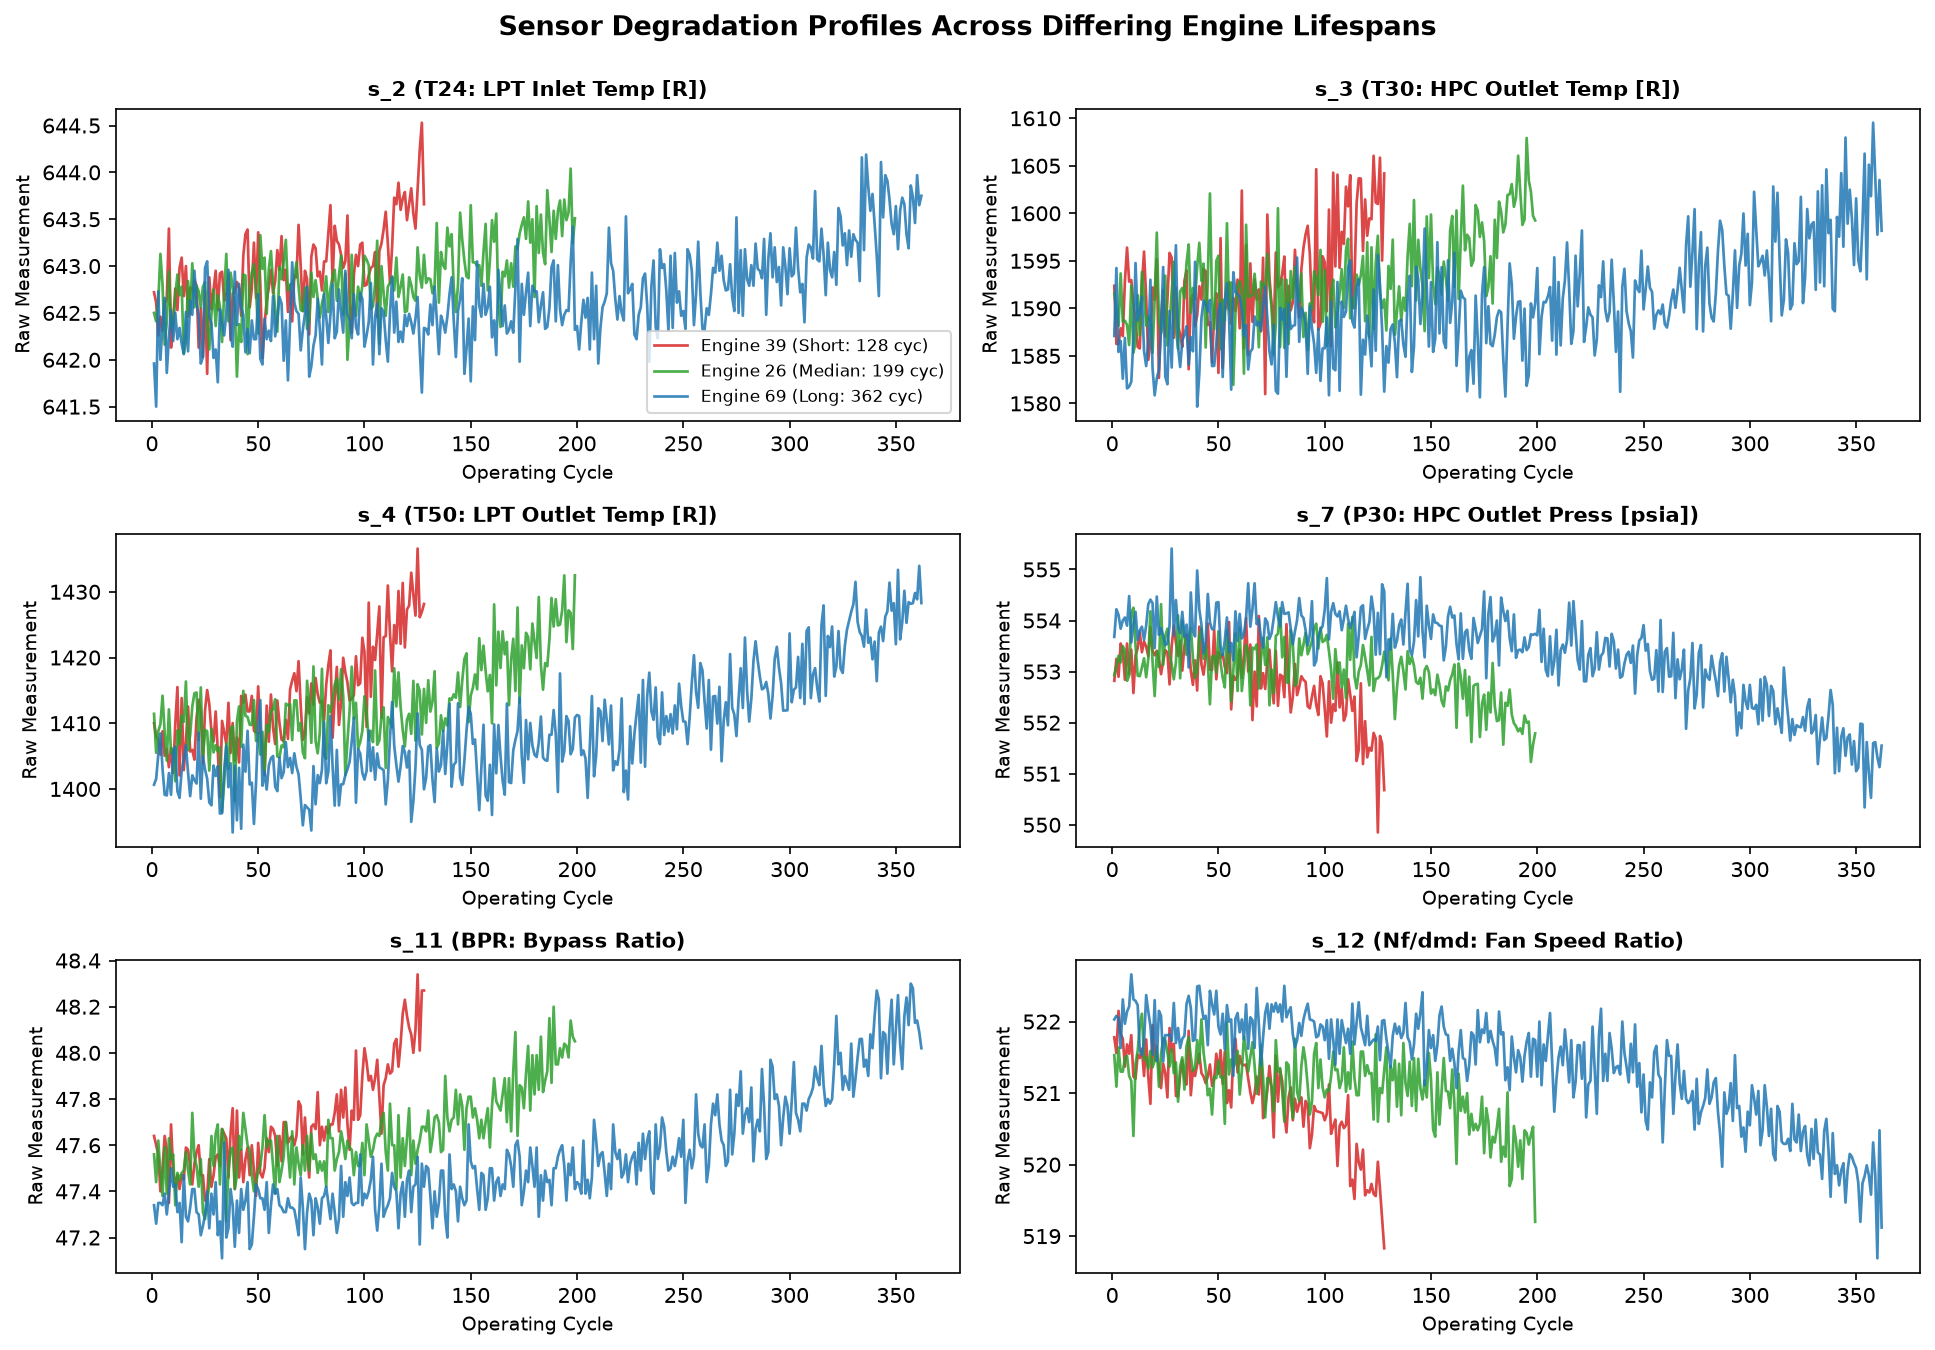

In [7]:
short_id = int(train_lifespans.idxmin())
median_id = int((train_lifespans - train_lifespans.median()).abs().idxmin())
long_id = int(train_lifespans.idxmax())

sample_ids = [short_id, median_id, long_id]
sample_labels = [f'Engine {short_id} (Short: {train_lifespans[short_id]} cyc)',
                 f'Engine {median_id} (Median: {train_lifespans[median_id]} cyc)',
                 f'Engine {long_id} (Long: {train_lifespans[long_id]} cyc)']

key_sensors = ['s_2', 's_3', 's_4', 's_7', 's_11', 's_12']
sensor_descriptions = {
    's_2': 's_2 (T24: LPT Inlet Temp [R])',
    's_3': 's_3 (T30: HPC Outlet Temp [R])',
    's_4': 's_4 (T50: LPT Outlet Temp [R])',
    's_7': 's_7 (P30: HPC Outlet Press [psia])',
    's_11': 's_11 (BPR: Bypass Ratio)',
    's_12': 's_12 (Nf/dmd: Fan Speed Ratio)'
}

fig, axes = plt.subplots(3, 2, figsize=(13, 9), dpi=150)
axes = axes.flatten()
colors_eng = ['#d62728', '#2ca02c', '#1f77b4']

for idx, s in enumerate(key_sensors):
    ax = axes[idx]
    for eng_id, label, color in zip(sample_ids, sample_labels, colors_eng):
        eng_data = train_df[train_df['engine_id'] == eng_id]
        ax.plot(eng_data['cycle'], eng_data[s], label=label, color=color, alpha=0.85, linewidth=1.3)
    ax.set_title(sensor_descriptions[s], fontsize=10, fontweight='bold')
    ax.set_xlabel('Operating Cycle', fontsize=9)
    ax.set_ylabel('Raw Measurement', fontsize=9)
    if idx == 0:
        ax.legend(frameon=True, facecolor='white', fontsize=8)

plt.suptitle('Sensor Degradation Profiles Across Differing Engine Lifespans', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## 6. Population-Normalized Degradation Curve (% Lifecycle)

Because engines fail at differing absolute cycle counts ($T_i \in [128, 362]$), we map each cycle to its fractional lifecycle:
$$\tau = \frac{t}{T_i} \times 100 \in [0, 100]$$
We compute population mean $\mu(\tau)$ and empirical dispersion $\sigma(\tau)$ across all 100 training engines.


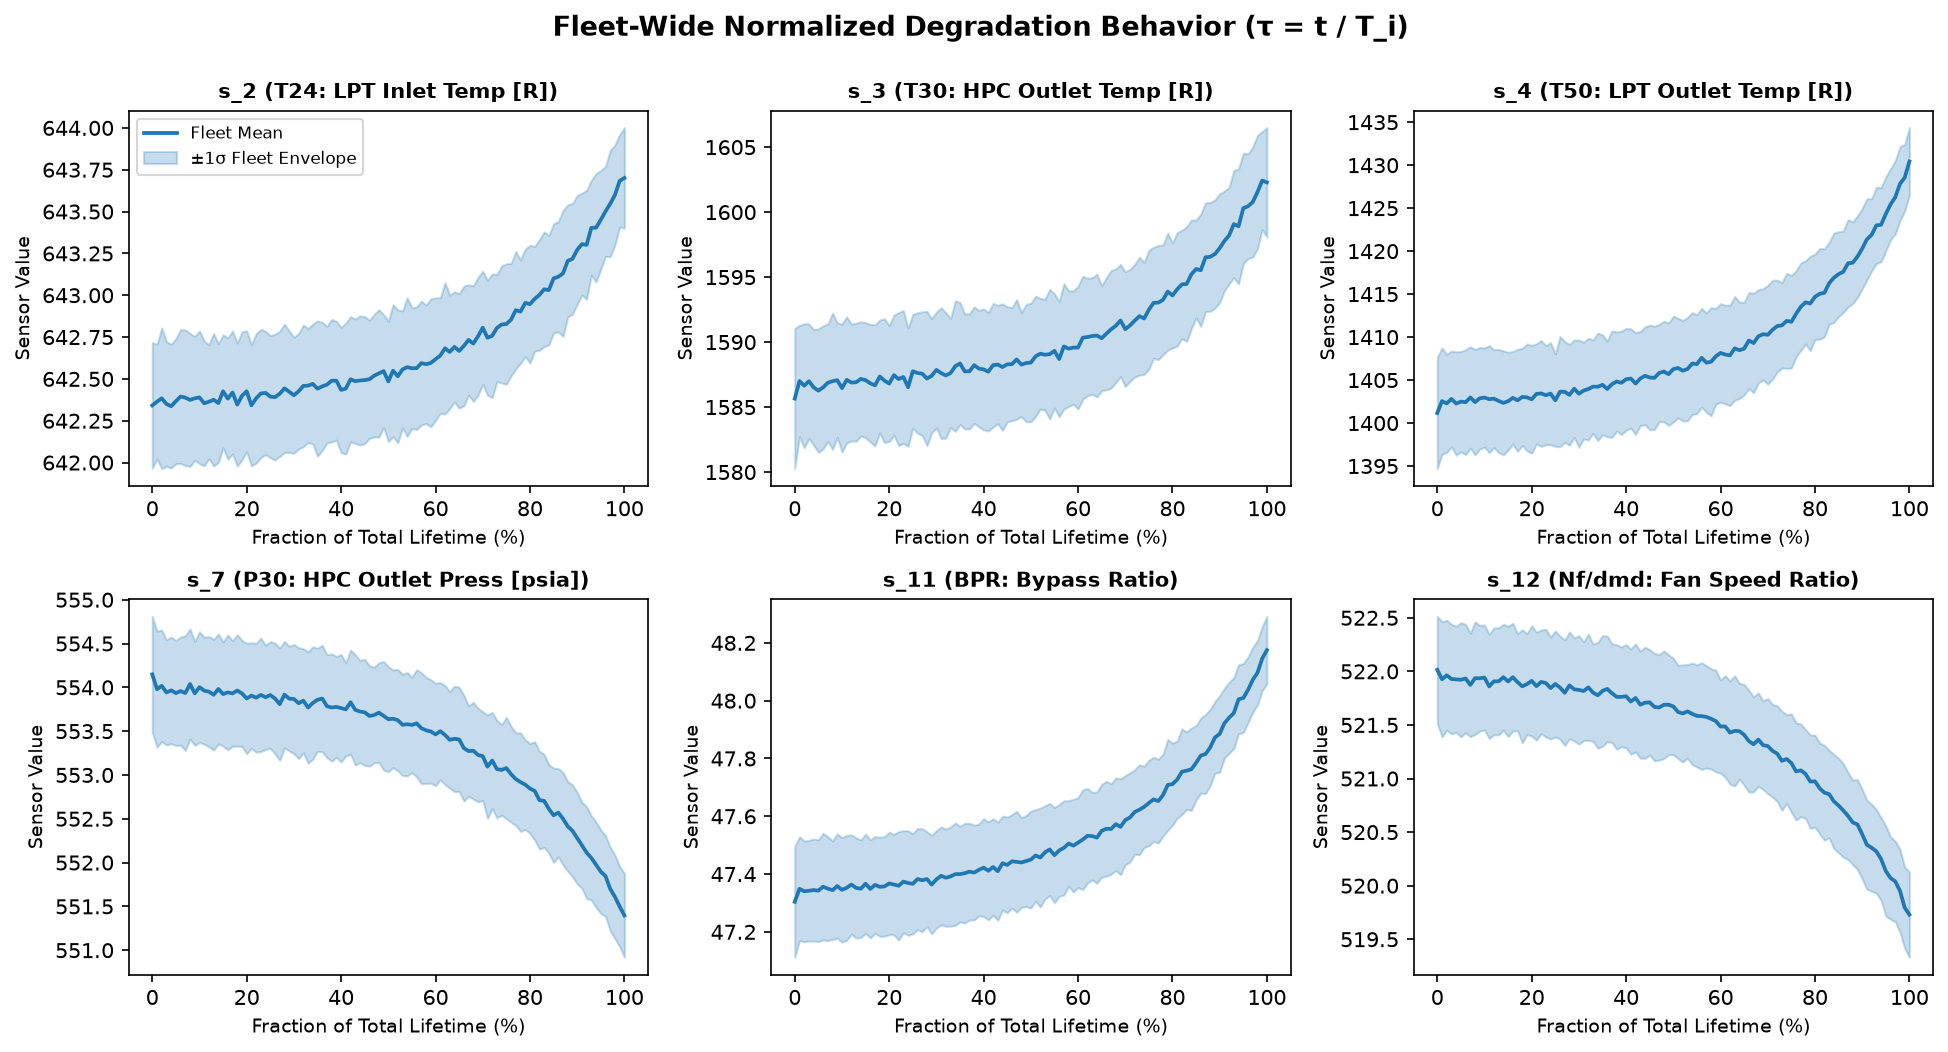

In [8]:
df_norm = train_df.copy()
max_cycles = df_norm.groupby('engine_id')['cycle'].transform('max')
df_norm['life_pct'] = (df_norm['cycle'] / max_cycles * 100).round().astype(int)

grouped_norm = df_norm.groupby('life_pct')[key_sensors]
mean_norm = grouped_norm.mean()
std_norm = grouped_norm.std()

fig, axes = plt.subplots(2, 3, figsize=(13, 7), dpi=150)
axes = axes.flatten()

for idx, s in enumerate(key_sensors):
    ax = axes[idx]
    pct = mean_norm.index
    mu = mean_norm[s]
    sigma = std_norm[s]
    ax.plot(pct, mu, color='#1f77b4', linewidth=1.8, label='Fleet Mean')
    ax.fill_between(pct, mu - sigma, mu + sigma, color='#1f77b4', alpha=0.25, label='±1σ Fleet Envelope')
    ax.set_title(sensor_descriptions[s], fontsize=10, fontweight='bold')
    ax.set_xlabel('Fraction of Total Lifetime (%)', fontsize=9)
    ax.set_ylabel('Sensor Value', fontsize=9)
    if idx == 0:
        ax.legend(frameon=True, facecolor='white', fontsize=8)

plt.suptitle('Fleet-Wide Normalized Degradation Behavior (τ = t / T_i)', fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()


## 7. Key Analytical Takeaways & Implications for Feature Engineering

1. **Non-Linear Degradation Trajectory (Piecewise / Exponential):**
   - From $\tau = 0\%$ to $\tau \approx 60-70\%$, sensors exhibit stationary, mean-reverting behavior (nominal wear).
   - Past $\tau \approx 70\%$, degradation accelerates exponentially toward catastrophic HPC failure.
   - **Implication for Target Formulation:** Capping the target RUL ($RUL_{\text{capped}} = \min(RUL, RUL_{\text{cap}})$) at values around $100-130$ cycles reflects this physics, preventing models from attempting to predict subtle differences during the flat healthy phase.
2. **Channel Pruning Strategy:**
   - Exclude $8$ non-informative channels: $\text{setting}_3, s_1, s_5, s_6, s_{10}, s_{16}, s_{18}, s_{19}$.
   - Retain $14$ informative sensors: $s_2, s_3, s_4, s_7, s_8, s_9, s_{11}, s_{12}, s_{13}, s_{14}, s_{15}, s_{17}, s_{20}, s_{21}$, along with flight settings $\text{setting}_1, \text{setting}_2$.
3. **Temporal Features Required:**
   - Raw measurements alone cannot capture the *rate* of degradation ($dx/dt$).
   - Rolling statistics (moving averages, rolling standard deviations) and first differences ($\Delta x_t = x_t - x_{t-w}$) will provide the necessary derivative signals to distinguish early-stage stability from end-of-life acceleration.
